# URP6295 | Duval County Tract-Level Land-Cover Analyzer

**Question:** Which Duval County census tracts show the greatest estimated vegetation decline and increase in built-up candidate area between 2017 and 2025, including within FEMA flood hazard areas?

**System:** A reproducible Python program that takes **one record per census tract**, validates the inputs, derives new change indicators, ranks tracts, and exports a new tract-level screening dataset. Satellite classification remains part of GIS5038C; **Python does the spatial-unit comparison and ranking**.

**Important:** This notebook includes a six-tract **synthetic DEMO** input for testing only. Switch `USE_DEMO` to `False` after exporting your *real* tract CSV from Earth Engine. Never cite demo outputs as Jacksonville research findings.

## 0. Setup and data structures
- **DataFrame**: tabular tract records; enables column-wise arithmetic and sorting.
- **Dictionary**: class-to-label lookup; keeps code readable.
- **List**: required input fields and exported output fields.
- **Functions**: reusable validation and transformation operations.

In [4]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from google.colab import drive
drive.mount('/content/drive/')

DATA_DIR = Path('/content/drive/My Drive/Colab Notebooks/Urban_Data_Labs/final')

OUTPUT_DIR = DATA_DIR / 'outputs'
OUTPUT_DIR.mkdir(exist_ok=True)
USE_DEMO = False
INPUT_FILE = ('Duval_Tract_LandCover_2017_2025.csv')
class_labels = {'veg': 'Vegetation', 'built': 'Built-up candidate'}


Drive already mounted at /content/drive/; to attempt to forcibly remount, call drive.mount("/content/drive/", force_remount=True).


## 1. Input and representation
One record is one Census tract (`GEOID`) with 2017 and 2025 areas in km², both countywide portions and the portions intersecting FEMA zones. The `valid_land_km2` field is the common land area available for comparison, not the total polygon area. The GEE export uses the same classified rasters and flood mask as GIS5038C.

In [5]:
tracts = pd.read_csv(DATA_DIR / INPUT_FILE, dtype={'GEOID': str, 'NAME': str})
print('Rows:', len(tracts), '| Columns:', len(tracts.columns))
print(tracts.head().to_string(index=False))

Rows: 219 | Columns: 11
      GEOID NAME  veg_2017  veg_2025  built_2017  built_2025  fema_veg_2017  fema_veg_2025  fema_built_2017  fema_built_2025  valid_land_km2
12031000200    2  2.456001  2.206317    0.978984    1.221207       0.240552       0.215669         0.047339         0.071639        3.832172
12031000300    3  1.422901  1.368060    1.255361    1.289350       0.051721       0.045012         0.046286         0.051740        2.912774
12031000600    6  2.919886  2.806666    1.032827    1.091309       0.191732       0.182841         0.048268         0.054508        4.410197
12031000700    7  2.757782  2.707856    0.319134    0.330129       0.161973       0.156472         0.069191         0.066890        3.304659
12031000800    8  0.983142  0.840101    0.759201    0.798929       0.256439       0.240543         0.199125         0.172137        2.228736


## 2. Input validation
Reject missing columns, repeated tract IDs, negative values, impossible FEMA subset areas, and class areas larger than valid land. This guards against common CSV and geoprocessing mistakes.

In [6]:
required = ['GEOID','NAME','veg_2017','veg_2025','built_2017','built_2025',
            'fema_veg_2017','fema_veg_2025','fema_built_2017',
            'fema_built_2025','valid_land_km2']
area_cols = required[2:]

def validate_tracts(table):
    missing = set(required) - set(table.columns)
    if missing: raise ValueError(f'Missing columns: {sorted(missing)}')
    if table[required].isna().any().any(): raise ValueError('Missing input values')
    if table['GEOID'].duplicated().any(): raise ValueError('Repeated tract GEOID')
    values = table[area_cols].apply(pd.to_numeric, errors='coerce')
    if values.isna().any().any(): raise ValueError('Non-numeric area detected')
    if (values < 0).any().any(): raise ValueError('Negative area detected')
    tol = 1e-5
    for year in [2017, 2025]:
        if ((values[f'veg_{year}'] + values[f'built_{year}']) > values['valid_land_km2'] + tol).any():
            raise ValueError(f'Classified areas exceed valid land in {year}')
        for cls in ['veg', 'built']:
            if (values[f'fema_{cls}_{year}'] > values[f'{cls}_{year}'] + tol).any():
                raise ValueError(f'FEMA {cls} area exceeds tract {cls} area ({year})')
    return True

assert validate_tracts(tracts)
print('Passed input validity checks.')

Passed input validity checks.


## 3. Operations: create NEW tract-level indicators
For each tract, calculate net change (2025 minus 2017), convert to hectares, and find the change in the share of valid land. We calculate comparable FEMA-only changes, too. These are change indicators, **not pixel-by-pixel conversion or flood-risk predictions**.

In [16]:
def make_change_table(table):
    out = table[['GEOID','NAME','valid_land_km2']].copy()
    for cls in ['veg','built']:
        out[f'{cls}_change_km2'] = table[f'{cls}_2025'] - table[f'{cls}_2017']
        out[f'{cls}_change_ha'] = 100 * out[f'{cls}_change_km2']
        out[f'{cls}_share_change_pp'] = np.where(
            table['valid_land_km2'] > 0,
            100 * out[f'{cls}_change_km2'] / table['valid_land_km2'], np.nan)
        out[f'fema_{cls}_change_km2'] = (
            table[f'fema_{cls}_2025'] - table[f'fema_{cls}_2017'])
    out['veg_loss_ha'] = (-out['veg_change_ha']).clip(lower=0)
    out['built_gain_ha'] = out['built_change_ha'].clip(lower=0)
    # Descriptive screening flag: NOT a measure of flood risk.
    out['screening_flag'] = (
    (out['veg_change_km2'] < 0) &
    (out['built_change_km2'] > 0) &
    (out['fema_built_change_km2'] > 0)
)
    return out

result = make_change_table(tracts)
print(result[['GEOID','veg_loss_ha','built_gain_ha',
              'fema_built_change_km2','screening_flag']].head().round(2).to_string(index=False))

      GEOID  veg_loss_ha  built_gain_ha  fema_built_change_km2  screening_flag
12031000200        24.97          24.22                   0.02            True
12031000300         5.48           3.40                   0.01            True
12031000600        11.32           5.85                   0.01            True
12031000700         4.99           1.10                  -0.00           False
12031000800        14.30           3.97                  -0.03           False


## 4. New output: rank tracts and save a screening dataset
The primary output is **a new CSV** containing tract-level derived fields and screening flags. A second CSV lists tracts with the largest estimated vegetation loss. The screening flag only identifies a pattern warranting a closer look; it does not prove land conversion, flooding, or need.

In [17]:
ranked = result.sort_values(['veg_loss_ha', 'built_gain_ha'], ascending=False).reset_index(drop=True)
ranked.insert(0, 'veg_loss_rank', np.arange(1, len(ranked)+1))
ranked.to_csv(OUTPUT_DIR / 'tract_change_indicators.csv', index=False)
ranked.head(10).to_csv(OUTPUT_DIR / 'top10_vegetation_loss.csv', index=False)
print(ranked[['veg_loss_rank','GEOID','veg_loss_ha','built_gain_ha',
              'screening_flag']].head(10).round(2).to_string(index=False))
print('Saved NEW data tables to', OUTPUT_DIR)

 veg_loss_rank       GEOID  veg_loss_ha  built_gain_ha  screening_flag
             1 12031010107       389.54         289.53            True
             2 12031014423       344.42         249.10            True
             3 12031010601       323.59         224.91            True
             4 12031010301       317.48         250.40            True
             5 12031017300       234.43         235.13           False
             6 12031010501       220.20         177.68            True
             7 12031010202       188.35          68.49            True
             8 12031010602       164.46         124.50           False
             9 12031014424       144.69         113.90            True
            10 12031010105       128.43          79.48            True
Saved NEW data tables to /content/drive/My Drive/Colab Notebooks/Urban_Data_Labs/final/outputs


## 5. Visualization: display (not substitute for) new data
Use a chart to communicate the derived tract ranking. The CSV, not the chart, is the primary output.

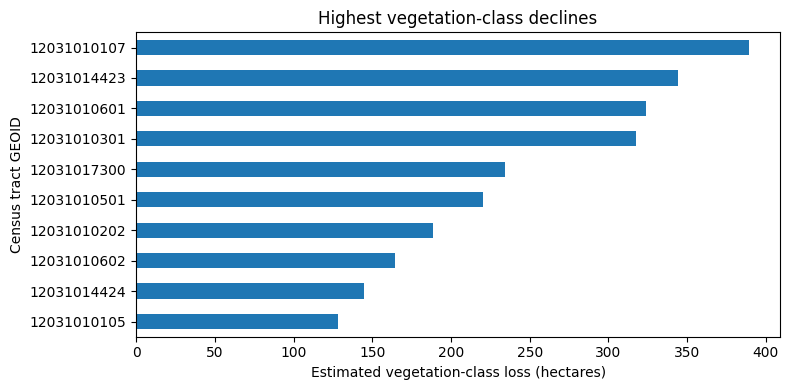

In [18]:
show = ranked.head(10).iloc[::-1]
ax = show.plot.barh(x='GEOID', y='veg_loss_ha', legend=False, figsize=(8,4))
ax.set_xlabel('Estimated vegetation-class loss (hectares)')
ax.set_ylabel('Census tract GEOID')
ax.set_title('Highest vegetation-class declines' + (' — DEMO DATA' if USE_DEMO else ''))
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'tract_vegetation_loss.png', dpi=170)
plt.show()

## 6. Independent checks and known-answer tests
Validate that the new changes reconcile to their input arithmetic and that 1 km² converts to 100 ha. Test whether invalid input correctly triggers an error. Then summarize separately the sample-based classification agreement from your GIS5038C confusion matrices.

In [19]:
assert np.allclose(result['veg_change_km2'].to_numpy(),
                   (tracts['veg_2025']-tracts['veg_2017']).to_numpy())
assert np.allclose(result['built_change_ha'].to_numpy(),
                   (tracts['built_2025']-tracts['built_2017']).to_numpy()*100)
assert (ranked['veg_loss_ha'].diff().fillna(0) <= 1e-8).all()

broken = tracts.copy()
broken.loc[0, 'veg_2017'] = -1
try:
    validate_tracts(broken)
    raise AssertionError('Invalid negative area was not rejected')
except ValueError:
    print('Known failure test passed: negative area rejected')

accuracies=[]
for year in [2017, 2025]:
    cm = pd.read_csv(DATA_DIR / f'Confusion_Matrix_{year}.csv', index_col=0)
    cm.index = cm.index.astype(int)
    cm.columns = cm.columns.astype(int)
    cm = cm.reindex(index=[0,1,2], columns=[0,1,2], fill_value=0)
    count = int(cm.to_numpy().sum())
    correct = int(np.trace(cm.to_numpy()))
    accuracies.append({'year':year,'sample_count':count,'correct':correct,
                       'sample_agreement_pct':100*correct/count})
acc = pd.DataFrame(accuracies)
acc.to_csv(OUTPUT_DIR / 'classification_sample_agreement.csv', index=False)
print(acc.to_string(index=False))
print('Arithmetic and ranking checks passed.')

Known failure test passed: negative area rejected
 year  sample_count  correct  sample_agreement_pct
 2017            30       22             73.333333
 2025            30       20             66.666667
Arithmetic and ranking checks passed.


In [20]:

# PART 9: Final Results and Sanity Checks

# Summarize all census tracts
print("Total census tracts:", len(tracts))

print("\nCountywide totals from tract data:")
print(tracts[
    ['veg_2017', 'veg_2025',
     'built_2017', 'built_2025']
].sum().round(2))

print("\nTotal estimated changes:")
print(result[
    ['veg_change_km2', 'built_change_km2',
     'fema_veg_change_km2',
     'fema_built_change_km2']
].sum().round(2))

print("\nNumber of flagged tracts:")
print(result['screening_flag'].sum())

print("\nHighest vegetation-loss tracts:")
print(ranked[
    ['GEOID', 'veg_loss_ha',
     'built_gain_ha', 'screening_flag']
].head(10).round(2))


Total census tracts: 219

Countywide totals from tract data:
veg_2017      1741.17
veg_2025      1698.61
built_2017     169.80
built_2025     198.02
dtype: float64

Total estimated changes:
veg_change_km2          -42.55
built_change_km2         28.22
fema_veg_change_km2      -8.99
fema_built_change_km2     5.82
dtype: float64

Number of flagged tracts:
106

Highest vegetation-loss tracts:
         GEOID  veg_loss_ha  built_gain_ha  screening_flag
0  12031010107       389.54         289.53            True
1  12031014423       344.42         249.10            True
2  12031010601       323.59         224.91            True
3  12031010301       317.48         250.40            True
4  12031017300       234.43         235.13           False
5  12031010501       220.20         177.68            True
6  12031010202       188.35          68.49            True
7  12031010602       164.46         124.50           False
8  12031014424       144.69         113.90            True
9  12031010105   

## 7. Honest interpretation and limitations

- **Only the real tract export can support Jacksonville findings.** Demo figures are fabricated for testing.
- Census tracts vary in size; show both absolute change in hectares and share change in percentage points.
- The vegetation and built-up labels are threshold-based spectral classes with known confusion. An increase in a built-up candidate class is **not proof of new construction**.
- Tract-level net changes do not tell us whether the same pixels changed directly from vegetation to built-up.
- FEMA polygons indicate mapped flood exposure at one snapshot, not actual flood events or changing flood risk.
- The original classification uses 20 m analysis scale, while the satellite bands have different native resolutions; results are approximate.
- Compare totals against the original countywide exports with allowance for boundary and raster-grid differences; do **not** assume exact equality.

## 8. Deliverables and GitHub checklist

- `Duval_Tract_LandCover_2017_2025.csv` (**real** input exported from Earth Engine, not included until you run Part 19)
- This notebook, `README.md`, confusion matrices, and `input_example.png` / `output_example.png`
- `outputs/tract_change_indicators.csv`: main **new** output dataset
- `outputs/top10_vegetation_loss.csv`: ranked subset
- `outputs/classification_sample_agreement.csv`: cross-project quality measure
- Presentation and 5–10-page report explaining each data transformation and test
